# 02 - LoRA on SAM 3 (team stack)

The LoRA adaptation arm on the native `sam3` package (`Sam3MedSeg`), across all three
datasets: BUSI, Kvasir, MoNuSAC.

Three sections: **(1)** build the model and verify the adapters landed where we think
they did, **(2)** the results all three datasets share, **(3)** the learning curves.

Scoring is not reimplemented here. Section 2 calls `scripts/eval_lora.py`, the same
entry point `scripts/slurm/eval_lora.sbatch` runs on the cluster, which in turn calls
the shared six-metric `scripts/eval_model.py` that every arm uses. The numbers below
are therefore the numbers in the report table, by construction rather than by
coincidence.

History (in git, not the working tree): the SAM 1 prototype lives in this notebook's
earlier versions (147K/93.7M, 0.157%); the HF-transformers SAM 3 verification was
notebook 03_Sam3_explore.ipynb, removed after the team standardized on the native
stack (see commit 6d38175). An earlier cross-dataset (BUSI-trained on Kvasir)
section was dropped once the report scope settled on within-dataset results.

**Kernel: select the `sam3-native` env** (the only one with the `sam3` package).

In [1]:
#autoreload, so edits to .py files show without restarting
%load_ext autoreload
%autoreload 2

## 1. Setup and unit tests

Imports, the qualitative helpers, and the unit tests for the LoRA pieces. No model is
built here and nothing touches a GPU -- this section costs seconds.

The two `Sam3MedSeg` builds moved down to section 2.1, where they are first needed, so
that the results table (section 2) and the learning curves (section 3) can be run on
their own. Those two read a CSV and three text logs respectively, so the no-hardware
path through this notebook is: this section, then 2, then 3.

In [2]:
import sys
sys.path.insert(0, "../src")
sys.path.insert(0, "../scripts")      # eval_model.py / eval_lora.py live here

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

from medseg.data.medseg_data import DataConfig, build_dataloaders
from medseg.models import Sam3MedSeg
from medseg.utils.device import get_device

device = get_device()
print("device:", device)     # sam3-native env; mps on this Mac


# --- qualitative helpers (metrics come from the shared evaluator, not from here) ---
@torch.no_grad()
def predict_prob(model, image):
    """One image -> lesion-probability map at the image's own size (model outputs 512)."""
    model.eval()
    logits = model(image.unsqueeze(0).to(device))
    prob = torch.sigmoid(logits)
    return F.interpolate(prob, size=image.shape[-2:], mode="bilinear", align_corners=False)[0, 0].cpu()


def dice_of(prob, gt, thr=0.5):
    """Single-image Dice, for the panel titles only."""
    pred = (prob > thr).float()
    return (2 * (pred * gt).sum() / (pred.sum() + gt.sum() + 1e-6)).item()

device: mps


In [3]:
!pytest ../tests/test_lora.py -v

============================= test session starts ==============================
platform darwin -- Python 3.12.13, pytest-9.1.1, pluggy-1.6.0 -- /Users/nikhilclaude/anaconda3/envs/sam3-native/bin/python3.12
cachedir: .pytest_cache
rootdir: /Users/nikhilclaude/Documents/Projects/DeepLearning/group_project
plugins: anyio-4.14.2
collected 5 items                                                              

../tests/test_lora.py::test_output_shape PASSED                          [ 20%]
../tests/test_lora.py::test_zero_at_init PASSED                          [ 40%]
../tests/test_lora.py::test_param_count PASSED                           [ 60%]
../tests/test_lora.py::test_linear_with_lora PASSED                      [ 80%]
../tests/test_lora.py::test_lora_qkv_slices PASSED                       [100%]

============================== 5 passed in 1.00s ===============================


## 2. Results: all three datasets

One table for BUSI, Kvasir and MoNuSAC, from the shared evaluator rather than a
notebook-local metric. `scripts/eval_lora.py` reads each run's experiment config for the
two settings that must match training (`img_size` and `normalize`), loads that run's
checkpoint, and hands the model to `eval_model.evaluate`, which:

* scores at the model's own output resolution (512) and derives the NSD tolerance from
  it (2 px at 512), resizing ground truth to match rather than the other way round;
* drops MoNuSAC's Ambiguous class (5) as don't-care -- it has no training data and
  appears in 87 of 101 test images, so counting it would silently sink the score;
* macro-averages MoNuSAC over the nucleus classes present in each image.

`USE_CACHED = True` reads the CSV the cluster job already wrote. Set it to `False` to
re-run the evaluation locally through the identical code path -- correct but slow on a
Mac, since it rebuilds each backbone and runs ~430 forward passes at 1008 input.

In [4]:
from pathlib import Path

USE_CACHED = True                      # False -> recompute locally via eval_lora.score()
CSV = Path("../results/metrics/lora_eval.csv")
METRICS = ["precision", "recall", "f1", "iou", "dice", "nsd"]

if USE_CACHED:
    assert CSV.exists(), f"{CSV} not found -- run scripts/slurm/eval_lora.sbatch, or set USE_CACHED=False"
    scores = pd.read_csv(CSV)
else:
    from eval_lora import score, RUNS   # the exact entry point the cluster job uses
    for ds in RUNS:
        score(ds, device, csv_path=str(CSV))
    scores = pd.read_csv(CSV)

# one row per dataset/split; keep the last run of each if the CSV was appended to twice
scores = scores.drop_duplicates(subset=["dataset", "split"], keep="last")
print(f"eval raster: {sorted(scores.eval_size.unique())}   NSD tol: {sorted(scores.tol.unique())}")
scores

eval raster: [np.int64(512)]   NSD tol: [np.int64(2)]


,dataset,split,images,eval_size,tol,precision,recall,f1,iou,dice,nsd
0,busi,val,64,512,2,0.7822,0.8227,0.7819,0.7002,0.7819,0.3857
1,busi,test,131,512,2,0.7956,0.8279,0.7853,0.7072,0.7853,0.4009
2,kvasir,val,100,512,2,0.9489,0.9241,0.9269,0.8768,0.9269,0.6510
3,kvasir,test,200,512,2,0.9209,0.9409,0.9162,0.8655,0.9162,0.6586
4,monusac,val,21,512,2,0.8006,0.7377,0.7424,0.6169,0.7424,0.7247
5,monusac,test,101,512,2,0.8199,0.7477,0.7589,0.6379,0.7589,0.6340


In [5]:
# The report table: test split only.
test = scores[scores.split == "test"].set_index("dataset").loc[["busi", "kvasir", "monusac"]]

print(f"{'dataset':10s}{'images':>8s}" + "".join(f"{m:>11s}" for m in METRICS))
print("-" * (18 + 11 * len(METRICS)))
for ds, r in test.iterrows():
    print(f"{ds:10s}{int(r['images']):>8d}" + "".join(f"{r[m]:>11.4f}" for m in METRICS))

print("\nF1 == Dice for the binary sets by definition. MoNuSAC is macro-averaged over the\n"
      "four nucleus classes, each scored only on the images containing it, so its row is a\n"
      "different measurement from the other two -- three tasks, not a difficulty ranking.")

dataset     images  precision     recall         f1        iou       dice        nsd
------------------------------------------------------------------------------------
busi           131     0.7956     0.8279     0.7853     0.7072     0.7853     0.4009
kvasir         200     0.9209     0.9409     0.9162     0.8655     0.9162     0.6586
monusac        101     0.8199     0.7477     0.7589     0.6379     0.7589     0.6340

F1 == Dice for the binary sets by definition. MoNuSAC is macro-averaged over the
four nucleus classes, each scored only on the images containing it, so its row is a
different measurement from the other two -- three tasks, not a difficulty ranking.


### 2.1 Qualitative: BUSI and Kvasir

**This is where the model gets built, and where the notebook starts needing hardware.**
One build, ~1-2 min, ~1.8 GB of weights; each dataset's trained weights are loaded into
it in turn. The forward passes are at 1008x1008 -- the head emits 512, but SAM 3's
backbone input is fixed at 1008 -- so budget roughly 30-60 s per image on CPU against
under a second on an H100.

Columns are image, ground truth, LoRA prediction. There is deliberately no untrained
column: a randomly initialized head only demonstrates that noise is noise, and the
comparison that would actually support a claim about the adapters is another arm
(full fine-tuning, UNet, YOLO), not random weights.

**One image stands in for the split, so the number on it is the split's.** The third
panel's title reports the dataset's *test mean* Dice, read from the same
`results/metrics/lora_eval.csv` behind the section 2 table, not the displayed image's
own score -- a per-image number beside a hand-picked image reads as a claim about the
model in general. The word "mean" is in the label for that reason, and each cell prints
the shown image's own Dice alongside the mean so the gap is on the record.

Every figure writes a 200-dpi PNG to `results/figures/` for the report. Panel titles
carry the dataset name rather than the test index -- the index lives in the filename,
for traceability, since the report caption already names the row.

In [63]:
# The binary-arm model build, reused below (~1-2 min on Mac). Each dataset's trained
# weights are loaded into it in turn by show_binary.
model = Sam3MedSeg(finetune_mode="lora").to(device)

# injection targets: 32 fused-qkv layers in the vision backbone, each now wrapped by LoRA_qkv
blocks = model.backbone.backbone.vision_backbone.trunk.blocks
print(f"{len(blocks)} vision blocks | block[0].attn.qkv is now a {type(blocks[0].attn.qkv).__name__}")
print(blocks[0].attn.qkv)

# Freeze the 455M backbone, train only the adapters + FPN head. Expected:
#   1,066,113 / 455,105,921 (0.2343%) = 524,288 adapters (32 x 2 x 2*4*1024) + 541,825 head
# Any other number means the injection state is wrong (see docs/lora.md).
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"\n{trainable:,} / {total:,} trainable  ({100*trainable/total:.4f}%)")

32 vision blocks | block[0].attn.qkv is now a LoRA_qkv
LoRA_qkv(
  (qkv): Linear(in_features=1024, out_features=3072, bias=True)
  (lora_q): LoRALayer(
    (A): Linear(in_features=1024, out_features=4, bias=False)
    (B): Linear(in_features=4, out_features=1024, bias=False)
  )
  (lora_v): LoRALayer(
    (A): Linear(in_features=1024, out_features=4, bias=False)
    (B): Linear(in_features=4, out_features=1024, bias=False)
  )
)

1,066,113 / 455,105,921 trainable  (0.2343%)


In [64]:
import numpy as np

# Apparent text size in the report is PANEL_FS / PANEL_IN, not PANEL_FS alone -- the PNG
# is scaled to the column width, so raising both together changes nothing. To make the
# text read bigger, raise PANEL_FS and leave PANEL_IN; titles must stay short enough to fit.
# (Section 3's learning curves have their own constants, sized for a much smaller slot.)
PANEL_FS = 22          # qualitative panel titles (sections 2.1 / 2.2)
PANEL_IN = 5           # inches per square panel, shared by the binary and MoNuSAC figures

# Row labels for the report. The test index is an internal detail -- it goes in the
# filename for traceability, not on the figure.
DISPLAY = {"busi": "BUSI", "kvasir": "Kvasir", "monusac": "MoNuSAC"}

# Test-split means, straight from the section 2 CSV so the figures cannot disagree with
# the table. The panel shows ONE image as a stand-in, so its title carries the dataset
# mean rather than that image's own Dice -- "mean" is in the label because a per-image
# number next to a hand-picked image would be read as the score of what you're looking at.
TEST_MEAN = scores[scores.split == "test"].set_index("dataset")["dice"].to_dict()


def show_binary(dataset, model, idx=0, save=True):
    """Load `dataset`'s trained weights into `model` and show test image `idx`.

    Three panels: the image, its ground truth, and the LoRA prediction. The image is a
    qualitative stand-in; the quantitative claim is the dataset mean in the third title.
    `dataset` is "busi" or "kvasir" -- it drives both the checkpoint and the matching
    test data, so the two cannot be mismatched. 1 forward pass."""
    ckpt = torch.load(f"../checkpoints/sam3_lora_{dataset}_full_512/best.pt", map_location=device)
    model.load_state_dict(ckpt["model"])
    test_ds = build_dataloaders(DataConfig.from_yaml(f"../configs/data/{dataset}.yaml"))["test"].dataset
    print(f"{dataset}: ckpt epoch {ckpt['epoch']} (val Dice {ckpt['dice']:.4f})  |  {len(test_ds)} test images")
    assert idx < len(test_ds), f"idx={idx} past {len(test_ds)} images"

    s = test_ds[idx]
    img, m = s["image"], s["mask"][0]
    prob = predict_prob(model, img)
    img_np = img.permute(1, 2, 0).numpy()
    # mask the background so the overlay tints only the lesion, leaving the scan crisp
    gt_overlay = np.ma.masked_where(m.numpy() == 0, m.numpy())
    print(f"  showing test[{idx}] (its own dice {dice_of(prob, m):.3f}; "
          f"title reports the test mean {TEST_MEAN[dataset]:.3f})")

    fig, axes = plt.subplots(1, 3, figsize=(3 * PANEL_IN, PANEL_IN))
    axes[0].imshow(img_np)
    axes[0].set_title(DISPLAY.get(dataset, dataset), fontsize=PANEL_FS)
    axes[1].imshow(img_np)
    axes[1].imshow(gt_overlay, cmap="Reds", vmin=0, vmax=1, alpha=0.6)
    axes[1].set_title("ground truth", fontsize=PANEL_FS)
    axes[2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
    axes[2].set_title(f"prediction  (mean dice {TEST_MEAN[dataset]:.3f})", fontsize=PANEL_FS)
    for a in axes:
        a.axis("off")
    plt.tight_layout()

    if save:
        out = Path("../results/figures")
        out.mkdir(parents=True, exist_ok=True)
        path = out / f"{dataset}_test{idx}_lora.png"
        plt.savefig(path, dpi=200, bbox_inches="tight")
        print(f"wrote {path}")
    plt.show()

busi: ckpt epoch 16 (val Dice 0.7819)  |  131 test images
  showing test[1] (its own dice 0.977; title reports the test mean 0.785)
wrote ../results/figures/busi_test1_lora.png


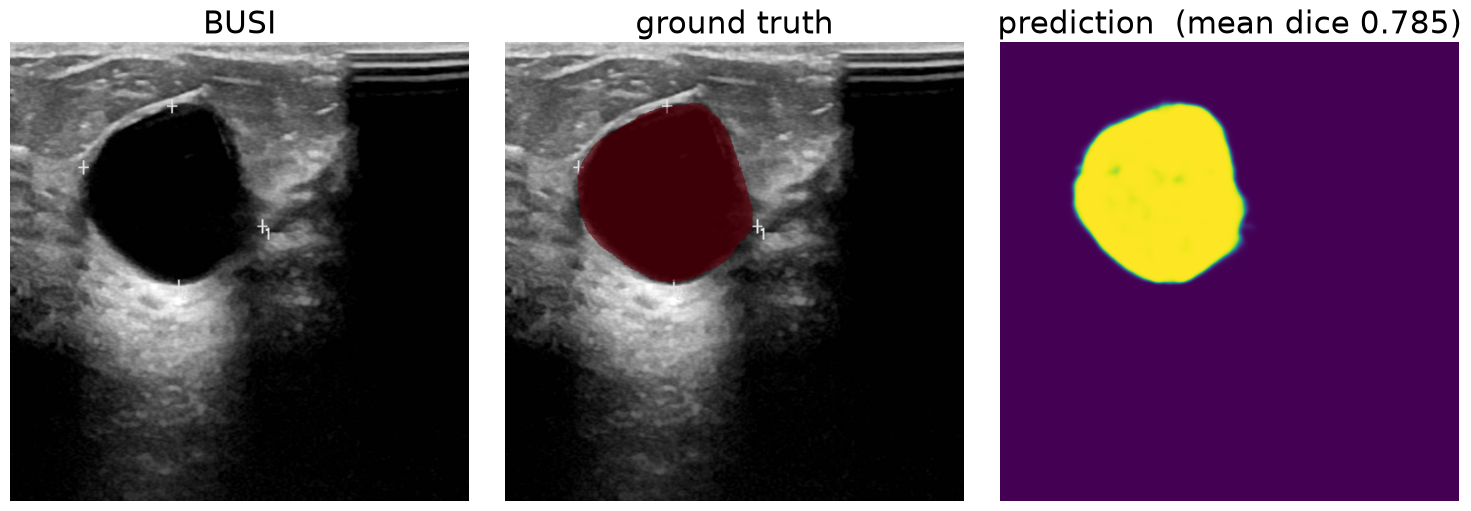

In [65]:
# BUSI - grayscale ultrasound, weak/diffuse boundaries
show_binary("busi", model, idx=1)

kvasir: ckpt epoch 18 (val Dice 0.9269)  |  200 test images
  showing test[0] (its own dice 0.980; title reports the test mean 0.916)
wrote ../results/figures/kvasir_test0_lora.png


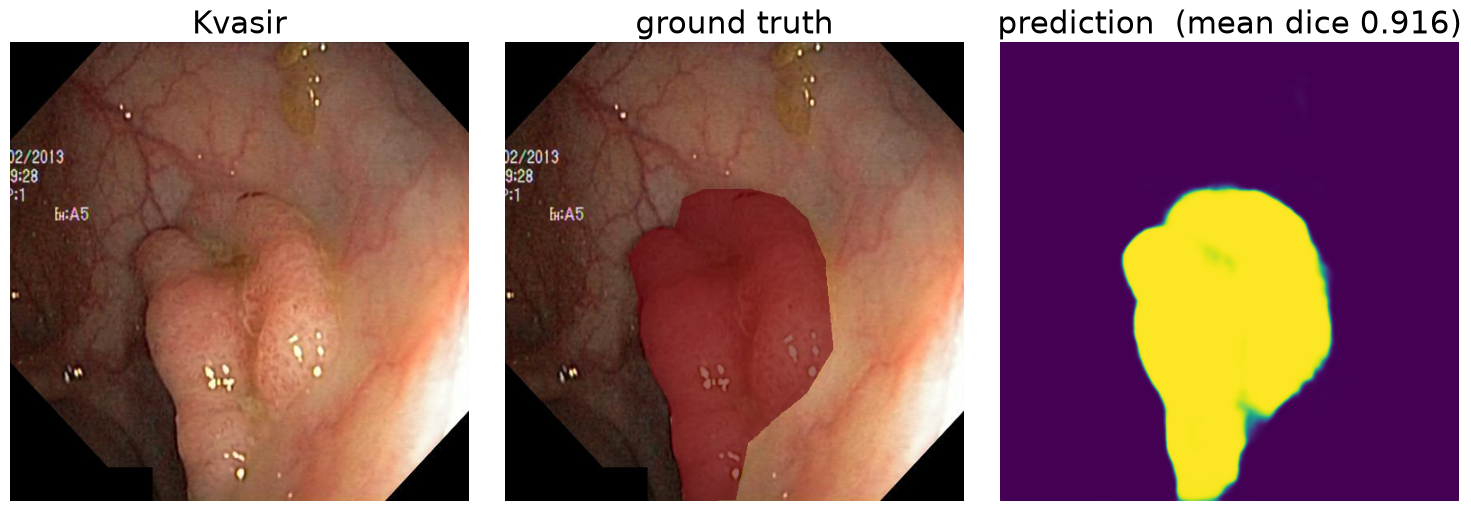

In [66]:
# Kvasir - RGB endoscopy, one large clear-boundaried polyp
show_binary("kvasir", model, idx=0)

### 2.2 Qualitative: MoNuSAC (multi-class)

The only multi-class arm: four nucleus types to separate rather than one object to find,
which needs its own model build. The head emits `num_classes` channels, so the 5-class
weights are a different set from the binary ones and `model` above cannot be reused.

Note Macrophage appears in only 53 of 188 train images, so the macro average leans on
the rare classes.

In [67]:
from pathlib import Path
import numpy as np
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

from medseg.engine.metrics import resize_mask, seg_scores

MONUSAC_LABELS = ["background", "Epithelial", "Lymphocyte", "Macrophage", "Neutrophil", "Ambiguous"]
MONUSAC_NC = 5          # trainable classes 0-4; class 5 is GT-only and ignored
AMBIGUOUS = 5
LEGEND_IN = 1.1         # inches added below the panels for the legend

# Wong/seaborn-colorblind steps for the four nucleus types: separated in hue AND
# lightness, so they survive colour-vision deficiency. Background near-white,
# Ambiguous mid-grey to read as "not a prediction target".
CLASS_COLORS = ["#f7f7f7", "#0173B2", "#DE8F05", "#029E73", "#CC78BC", "#999999"]
MC_CMAP = ListedColormap(CLASS_COLORS)
MC_NORM = BoundaryNorm(np.arange(-0.5, 6.5, 1.0), MC_CMAP.N)


@torch.no_grad()
def predict_labels(model, image):
    """One image -> (H,W) predicted class indices at the image's own resolution."""
    model.eval()
    logits = model(image.unsqueeze(0).to(device))                    # (1,5,512,512)
    lab = logits.argmax(1, keepdim=True).float()
    lab = F.interpolate(lab, size=image.shape[-2:], mode="nearest")  # nearest: never invent a class
    return lab[0, 0].cpu().long()


def mc_legend(fig):
    """One figure-level legend in a single row under all panels."""
    fig.legend(handles=[Patch(facecolor=CLASS_COLORS[c],
                              label=MONUSAC_LABELS[c] + (" (ignored)" if c == AMBIGUOUS else ""))
                        for c in range(1, 6)],
               loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=5,
               frameon=False, fontsize=PANEL_FS - 5)


def show_monusac(model, test_ds, idx=5, save=True):
    """Image, ground truth and LoRA prediction for one test image. 1 forward pass.

    The image is a qualitative stand-in; the number in the third title is the test-set
    macro mean from section 2, not this image's score.

    Index 5 is one of only two test images containing all four nucleus types (the other
    is 90, which is 24.5% Ambiguous pixels and renders mostly grey). Do NOT use test[0:5]:
    they are consecutive, and MoNuSAC is ordered by patient/organ, so they all show a
    single nucleus type and make a multi-class task look binary.
    Richer alternatives, 3 types each: 10, 46, 77.
    """
    # The legend gets its OWN inch of figure height on top of the panel grid; carving it
    # out of a fixed height instead would shrink these square images below the binary ones.
    fig_h = PANEL_IN + LEGEND_IN
    fig, axes = plt.subplots(1, 3, figsize=(3 * PANEL_IN, fig_h))

    s = test_ds[idx]
    img, gt = s["image"], s["mask"]                       # (3,H,W), (H,W) long
    img_np = img.permute(1, 2, 0).numpy()

    lab_t = predict_labels(model, img)
    # this image's own macro Dice -- printed for the record, not put on the figure
    d_t = seg_scores(F.one_hot(lab_t, MONUSAC_NC).permute(2, 0, 1)[None].float(),
                     gt[None], tol=2, ignore_index=AMBIGUOUS)[0]
    print(f"  showing test[{idx}] (its own macro dice {d_t:.3f}; "
          f"title reports the test mean {TEST_MEAN['monusac']:.3f})")

    n_cls = len(set(gt.unique().tolist()) - {0, AMBIGUOUS})
    panels = [(img_np, None, f"MoNuSAC  ({n_cls} types)"),
              (gt.numpy(), MC_CMAP, "ground truth"),
              (lab_t.numpy(), MC_CMAP, f"prediction  (macro mean {TEST_MEAN['monusac']:.3f})")]
    for col, (data, cm, title) in enumerate(panels):
        axes[col].imshow(data, cmap=cm, norm=MC_NORM if cm is not None else None)
        axes[col].set_title(title, fontsize=PANEL_FS)
        axes[col].axis("off")

    mc_legend(fig)
    plt.tight_layout(rect=(0, LEGEND_IN / fig_h, 1, 1))

    if save:
        out = Path("../results/figures")
        out.mkdir(parents=True, exist_ok=True)
        path = out / f"monusac_test{idx}_lora.png"
        plt.savefig(path, dpi=200, bbox_inches="tight")
        print(f"wrote {path}")
    plt.show()

In [68]:
CKPT_MC = Path("../checkpoints/sam3_lora_monusac_full_512/best.pt")

model_mc = Sam3MedSeg(finetune_mode="lora", num_classes=MONUSAC_NC).to(device)

tr = sum(p.numel() for p in model_mc.parameters() if p.requires_grad)
tot = sum(p.numel() for p in model_mc.parameters())
print(f"{tr:,} / {tot:,} trainable  ({100*tr/tot:.4f}%)   [binary arm: 1,066,113]")
# the +516 over the binary arm is the head's final 1x1 conv going 128->5 instead of 128->1

if CKPT_MC.exists():
    ck = torch.load(CKPT_MC, map_location=device)
    model_mc.load_state_dict(ck["model"])
    print(f"loaded {CKPT_MC}  (epoch {ck['epoch']}, val Dice {ck['dice']:.4f})")
else:
    ck = None
    print(f"NOT FOUND: {CKPT_MC}\n"
          f"  Run:  sbatch scripts/slurm/train_lora.sbatch configs/experiment/lora/baseline/sam3_lora_monusac_full.yaml\n"
          f"  The cell below will show an untrained model until the checkpoint exists.")

1,066,629 / 455,106,437 trainable  (0.2344%)   [binary arm: 1,066,113]
loaded ../checkpoints/sam3_lora_monusac_full_512/best.pt  (epoch 19, val Dice 0.7424)


monusac TEST: 101 images
  showing test[5] (its own macro dice 0.711; title reports the test mean 0.759)
wrote ../results/figures/monusac_test5_lora.png


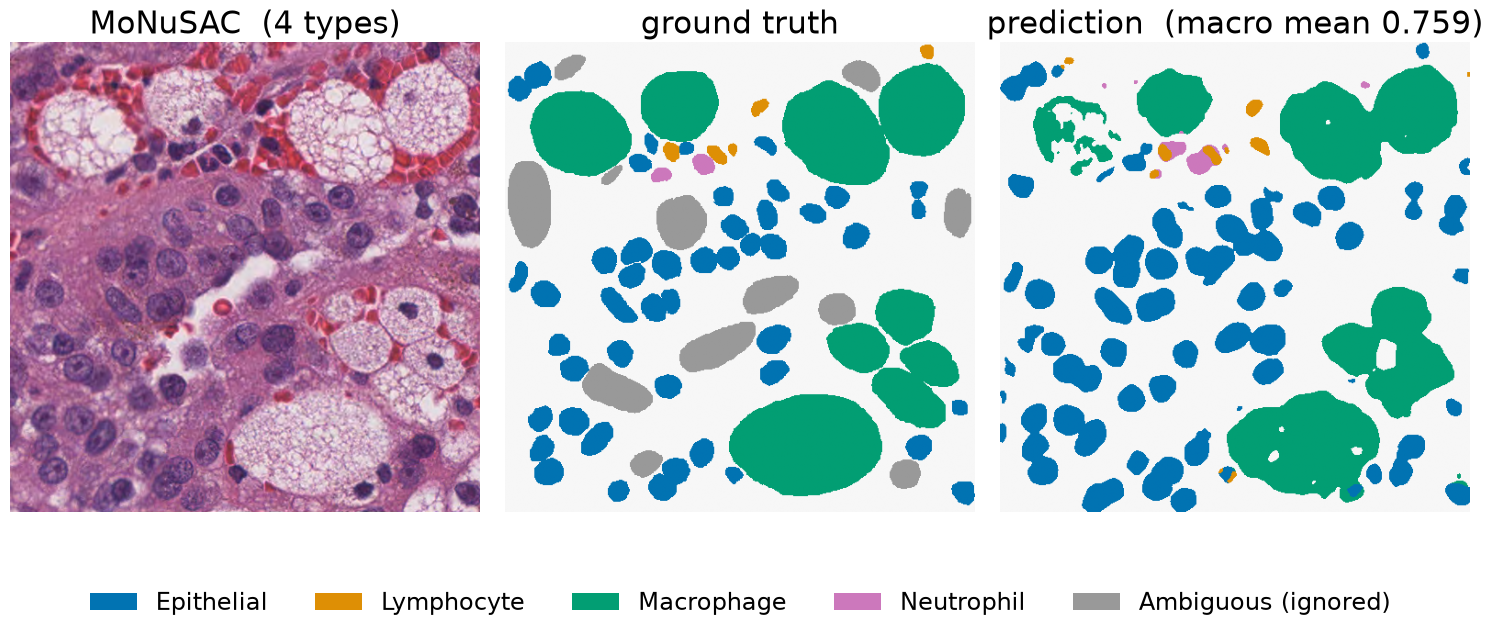

In [69]:
test_ds_mc = build_dataloaders(DataConfig.from_yaml("../configs/data/monusac.yaml"))["test"].dataset
print(f"monusac TEST: {len(test_ds_mc)} images")

# test[5] is one of only two images with all four nucleus types. test[0:5] are consecutive
# and MoNuSAC is ordered by patient/organ, so those five all show one type.
show_monusac(model_mc, test_ds_mc, idx=5)

## 3. Learning curves

The per-epoch history is not in the checkpoint -- `best.pt` stores only the single best
epoch. It is in the SLURM training logs, as the `epoch N: train_loss=... val_dice=...`
lines, which we parse here.

All three are the 512-head baselines of 2026-08-01, the same runs behind the table in
section 2. The dashed line marks the epoch that was actually saved.

wrote ../results/figures/lora_curve_busi.png


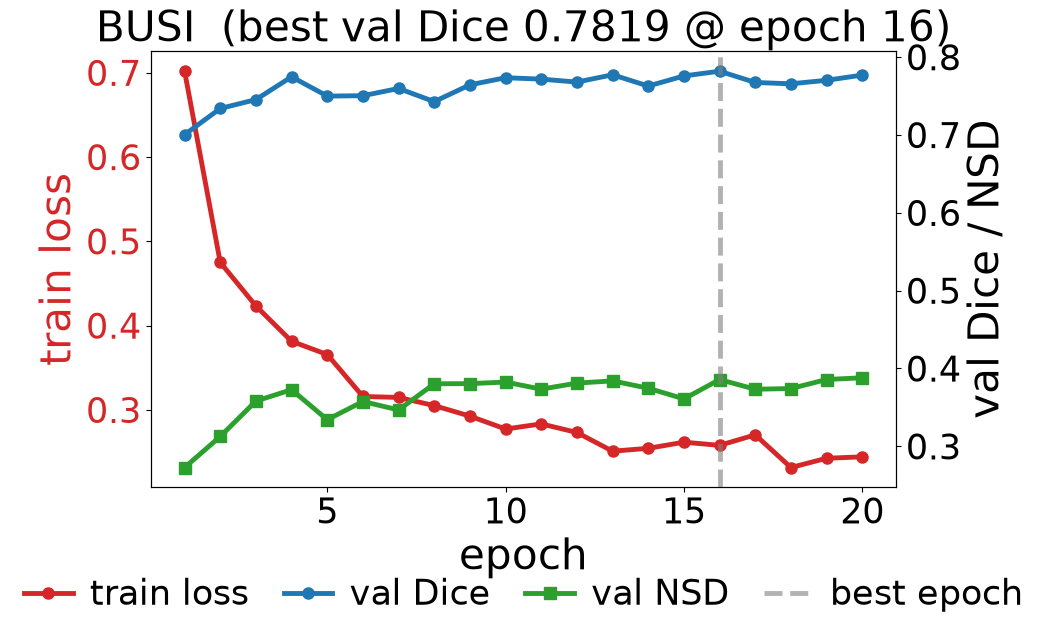

wrote ../results/figures/lora_curve_kvasir.png


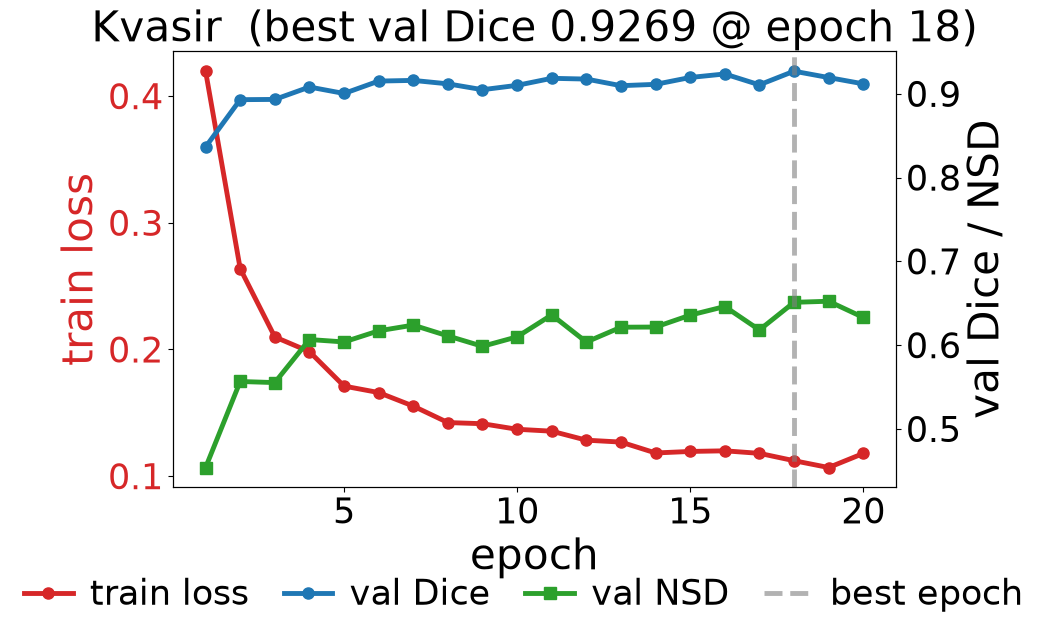

wrote ../results/figures/lora_curve_monusac.png


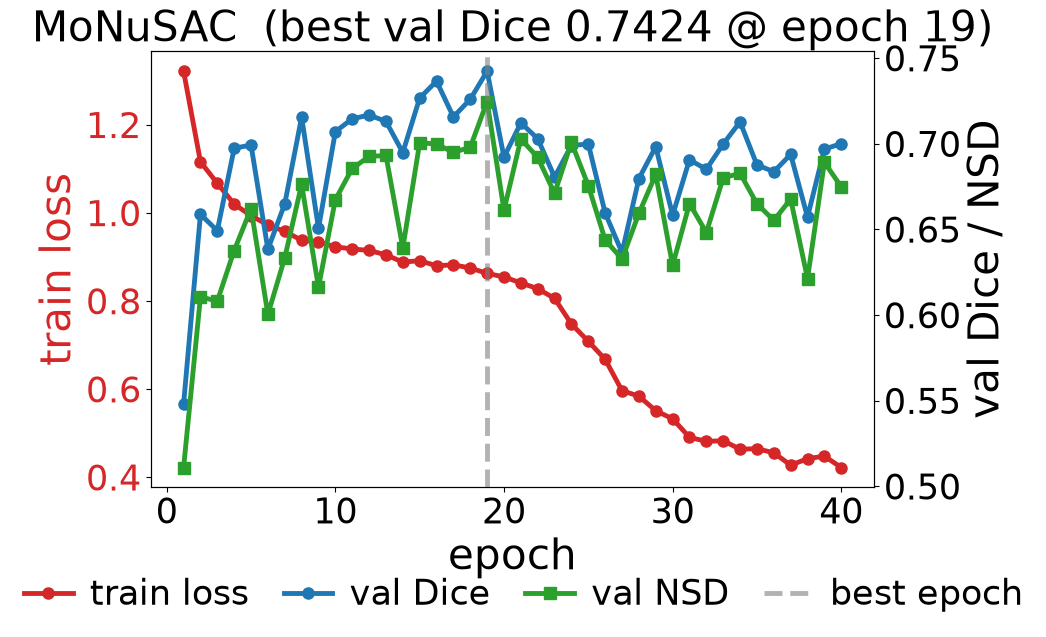

In [92]:
import re
from matplotlib.ticker import MaxNLocator

# --- learning-curve style knobs -------------------------------------------------
# What matters on the printed page is the RATIO font/width: the PNG is scaled to fit
# its slot, so 18pt on a 10in figure reads the same as 9pt on a 5in one. To make text
# bigger in the report, raise the FS values OR shrink CURVE_W -- not both.
CURVE_W = 10.0            # figure width, inches
CURVE_H = 6.0             # axes height, inches (legend strip is added below this)
CURVE_LEGEND_IN = 0.5     # height of the legend strip under the axes
CURVE_FS = 30            # axis labels + title
CURVE_TICK_FS = 25        # tick numbers
CURVE_LEGEND_FS = 25      # legend entries
CURVE_LW = 3.5            # line width (matplotlib default 1.5)
CURVE_MS = 8              # marker size (matplotlib default 6)
CURVE_BEST_LW = 3.5       # dashed best-epoch rule ONLY -- not covered by CURVE_LW;
                          # set to CURVE_LW to match the data series
CURVE_BEST_ALPHA = 0.6    # raise toward 1.0 to darken that rule
CURVE_NCOL = 4            # legend columns; 2 stacks it into two rows
CURVE_LEG_COLSPACE = 1.0  # gap BETWEEN legend entries (matplotlib default 2.0)
CURVE_LEG_HANDLELEN = 1.4 # length of each legend line sample (default 2.0)
CURVE_LEG_HANDLEPAD = 0.5 # gap between a sample and its text (default 0.8)
CURVE_MAX_TICKS = None    # e.g. 5 to thin the tick labels; None = matplotlib default
CURVE_DPI = 200
# --------------------------------------------------------------------------------


def parse_log(path):
    """Extract per-epoch (train_loss, val_dice, val_nsd) from a SLURM training log."""
    pat = re.compile(r"epoch (\d+): train_loss=([\d.]+)\s+val_dice=([\d.]+)\s+val_nsd=([\d.]+)")
    rows = [m for m in (pat.search(l) for l in open(path)) if m]
    if not rows:
        raise ValueError(f"no epoch lines in {path} -- wrong job id, or the run died early")
    ep = [int(m.group(1)) for m in rows]
    return ep, [float(m.group(2)) for m in rows], [float(m.group(3)) for m in rows], [float(m.group(4)) for m in rows]


def plot_curve(path, title, save=True):
    ep, tl, vd, vn = parse_log(path)
    # legend sits in its own strip below the axes -- inside the axes it lands on the
    # val Dice / NSD curves, which run flat across the right half on Kvasir and BUSI
    fig_h = CURVE_H + CURVE_LEGEND_IN
    fig, ax1 = plt.subplots(figsize=(CURVE_W, fig_h))
    l1, = ax1.plot(ep, tl, "C3-o", lw=CURVE_LW, ms=CURVE_MS, label="train loss")
    ax1.set_xlabel("epoch", fontsize=CURVE_FS)
    ax1.set_ylabel("train loss", color="C3", fontsize=CURVE_FS)
    ax1.tick_params(axis="x", labelsize=CURVE_TICK_FS)
    ax1.tick_params(axis="y", labelcolor="C3", labelsize=CURVE_TICK_FS)

    ax2 = ax1.twinx()
    l2, = ax2.plot(ep, vd, "C0-o", lw=CURVE_LW, ms=CURVE_MS, label="val Dice")
    l3, = ax2.plot(ep, vn, "C2-s", lw=CURVE_LW, ms=CURVE_MS, label="val NSD")
    ax2.set_ylabel("val Dice / NSD", fontsize=CURVE_FS)
    ax2.tick_params(axis="y", labelsize=CURVE_TICK_FS)

    best = max(range(len(vd)), key=lambda i: vd[i])
    lbest = ax2.axvline(ep[best], ls="--", lw=CURVE_BEST_LW, c="gray", alpha=CURVE_BEST_ALPHA, label="best epoch")

    if CURVE_MAX_TICKS:
        ax1.xaxis.set_major_locator(MaxNLocator(CURVE_MAX_TICKS, integer=True))
        ax1.yaxis.set_major_locator(MaxNLocator(CURVE_MAX_TICKS))
        ax2.yaxis.set_major_locator(MaxNLocator(CURVE_MAX_TICKS))

    lines = [l1, l2, l3, lbest]
    fig.legend(lines, [l.get_label() for l in lines], loc="lower center",
               bbox_to_anchor=(0.5, 0.0), ncol=CURVE_NCOL, frameon=False,
               fontsize=CURVE_LEGEND_FS, columnspacing=CURVE_LEG_COLSPACE,
               handlelength=CURVE_LEG_HANDLELEN, handletextpad=CURVE_LEG_HANDLEPAD)
    plt.title(f"{title}  (best val Dice {vd[best]:.4f} @ epoch {ep[best]})", fontsize=CURVE_FS)
    plt.tight_layout(rect=(0, CURVE_LEGEND_IN / fig_h, 1, 1))

    if save:
        out = Path("../results/figures")
        out.mkdir(parents=True, exist_ok=True)
        p = out / f"lora_curve_{title.lower()}.png"
        plt.savefig(p, dpi=CURVE_DPI, bbox_inches="tight")
        print(f"wrote {p}")
    plt.show()


# The 512-head baselines (2026-08-01). Job ids 5525699/5526204 are the earlier
# 256-data/1008-head era: their val_nsd is on a different scale (tol was hardcoded at
# 2px regardless of raster), so do not mix them into these plots.
plot_curve("../slurm_outs/lora/slurm_5554981.out", "BUSI")
plot_curve("../slurm_outs/lora/slurm_5554982.out", "Kvasir")
plot_curve("../slurm_outs/lora/slurm_5554983.out", "MoNuSAC")